In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import linear_model
from sklearn.metrics import(
    mean_squared_error, 
    mean_absolute_error,
    r2_score
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('CO2_Dataset.csv')

In [3]:
df.describe()

,engine,cylandr,fuelcomb,out1
count,500.000000,500.000000,500.000000,500.000000
mean,3.600400,6.132000,12.476600,268.026000
std,1.478191,1.832291,3.943025,67.099673
min,1.000000,4.000000,4.800000,110.000000
25%,2.000000,4.000000,9.500000,217.000000
50%,3.600000,6.000000,11.650000,260.000000
75%,5.000000,8.000000,14.800000,317.000000
max,6.800000,12.000000,25.800000,488.000000


<Axes: xlabel='out1', ylabel='count'>

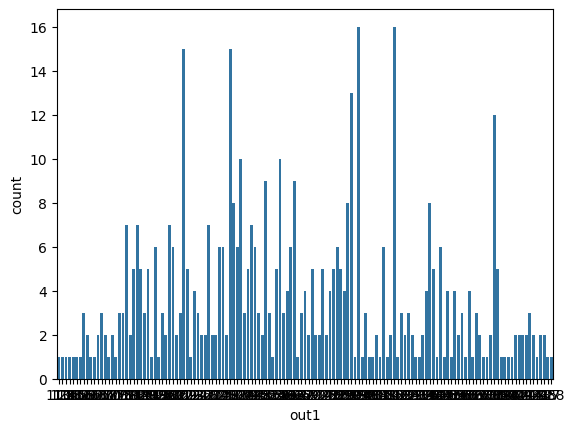

In [4]:
sns.countplot(x = 'out1', data = df)

<Axes: >

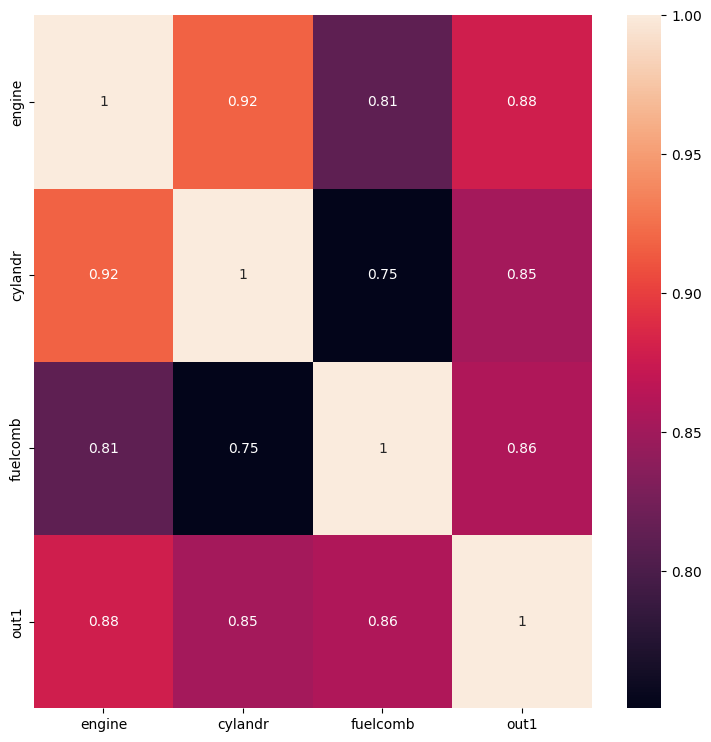

In [5]:
plt.subplots(figsize = (9,9))
sns.heatmap(df.corr(), annot = True)

In [6]:
#Split the data reproducibly
x = df.drop('out1', axis = 1)
y = df.out1

In [7]:
X_train, X_test, y_train, y_test = train_test_split(x, y,
                                                    test_size = 0.2,
                                                    random_state=42)

In [8]:
#Train, Fit, Make predictions and Evaluate the model
linear_reg = linear_model.LinearRegression()
random_reg = RandomForestRegressor(
    n_estimators=100, #Make a random forest with 100 trees
    random_state=42,
    max_depth=None
)

for model in (linear_reg, random_reg):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"\nModel: {model.__class__.__name__}"
          f"\nMSE: {mse:.2f}"
          f"\nMAE: {mae:.2f}"
          f"\nR² Score: {r2:.2f}")
    #print("MSE:", mean_squared_error(y_test, y_pred))
    #print("MAE:", mean_absolute_error(y_test, y_pred))
    #print("R² Score:", r2_score(y_test, y_pred))


Model: LinearRegression
MSE: 878.41
MAE: 22.40
R² Score: 0.85

Model: RandomForestRegressor
MSE: 284.98
MAE: 7.34
R² Score: 0.95


In [9]:
depths = [3, 5, 8, 10, 15, None]
for depth in depths:
    model = RandomForestRegressor(
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    print(
        f"Depth: {depth}, "
        f"Train MSE: {train_mse:.2f}, "
        f"Test MSE: {test_mse:.2f}"
    )

Depth: 3, Train MSE: 440.80, Test MSE: 685.75
Depth: 5, Train MSE: 222.89, Test MSE: 452.18
Depth: 8, Train MSE: 54.43, Test MSE: 301.87
Depth: 10, Train MSE: 43.32, Test MSE: 285.53
Depth: 15, Train MSE: 41.46, Test MSE: 285.00
Depth: None, Train MSE: 41.46, Test MSE: 284.98


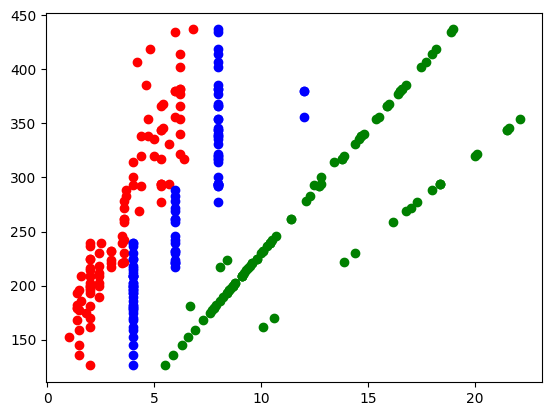

In [10]:
plt.scatter(X_test["engine"], y_test, color = 'red')
plt.scatter(X_test.fuelcomb, y_test, color = "green" )
plt.scatter(X_test.cylandr, y_test, color = "blue" )
plt.show()

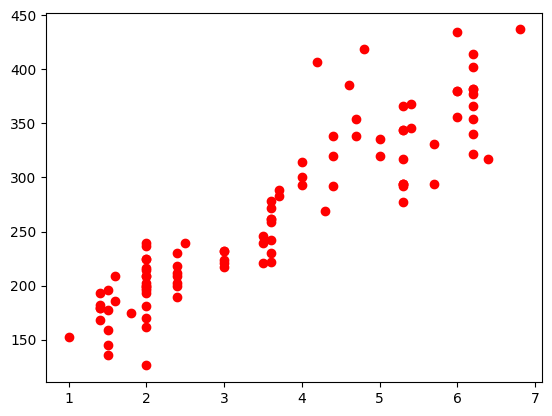

In [11]:
plt.scatter(X_test["engine"], y_test, color = 'red')
#plt.plot(X_test["engine"], y_pred, color = 'black', linewidth = 2)
plt.show()

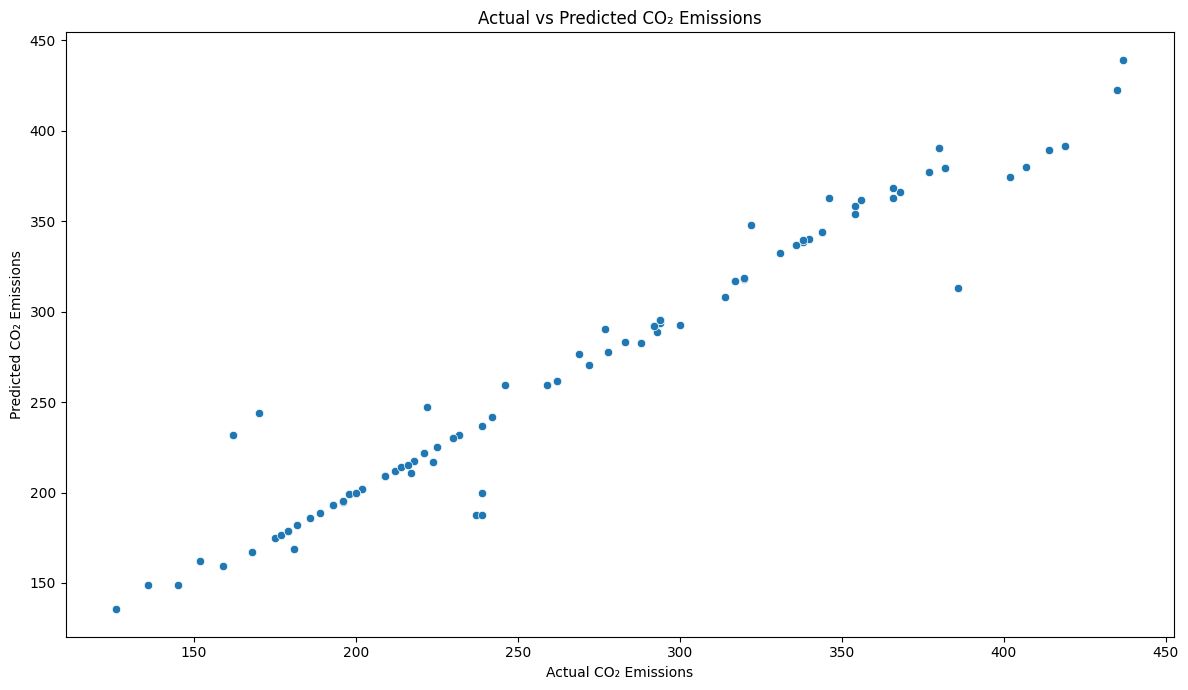

In [12]:
#Acual vs Predicted
plt.figure(figsize=(12, 7))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual CO₂ Emissions")
plt.ylabel("Predicted CO₂ Emissions")
plt.title("Actual vs Predicted CO₂ Emissions")
plt.tight_layout()
plt.show()

In [15]:
#Test Overfitting
y_train_pred = random_reg.predict(X_train)
y_test_pred = random_reg.predict(X_test)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"Train MSE: {train_mse}"
      f"\nTest MSE: {test_mse}")

Train MSE: 41.458502072335605
Test MSE: 284.9834505483731


In [66]:
BMW = np.array([[5.2, 10, 14.8]])

In [ ]:
co2 = linear_reg.predict(BMW)
co2

C:\Users\asus\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([345.38652164])